# Particles that touch the edge of the array

### What you will learn

1. what a particle cut by the edge of the diode array looks like;
2. how the engine marks it (`touching_edge`, reject code `'t'`) and how its size is affected;
3. what the optional partial-image measures in the enhancements package compute;
4. what is known about how often this happens;
5. how to look for it in your own data, and what is on by default.

### What data this uses

None from disk. Every image is *synthetic*: a disc of 24 pixels diameter placed at different
positions on a 32-diode array. Pixel size is assumed to be 10 µm.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts). **Related:** [05_images_in_pieces](05_images_in_pieces.ipynb). **Needs:** the enhancements package and `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What it looks like

An image is a boolean array, `True` where a diode was in shadow; time (slices) runs along the horizontal axis and
the diodes along the vertical axis, diode 1 at the top. The array has a fixed number of diodes. A particle whose shadow reaches the first or the
last diode may continue beyond the array, so the image shows only part of it. Below, the same
24-pixel disc is moved across a 32-diode array; the centre diode is given above each panel, and the disc is cut by the top or bottom edge of the panel.

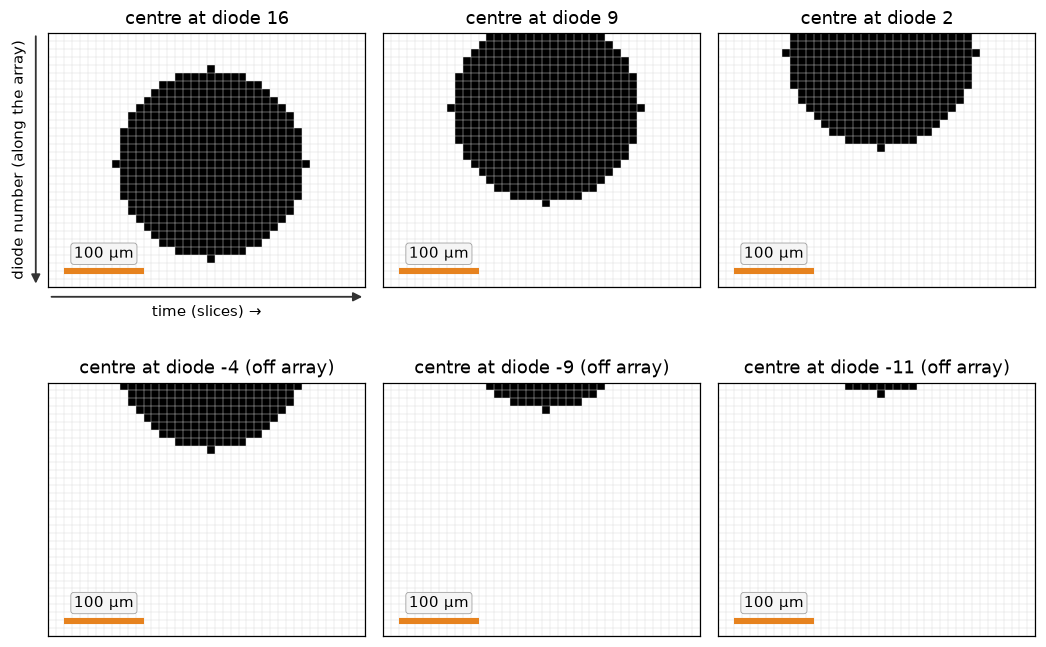

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import _style                  # house style: _style.py sits beside this notebook
_style.apply()

NDIODE, NSLICE, D = 32, 40, 24
PX_UM = 10.0
ii, jj = np.mgrid[0:NSLICE, 0:NDIODE]

def disc(centre_col, diameter=D):
    return (ii - NSLICE // 2) ** 2 + (jj - centre_col) ** 2 <= (diameter / 2) ** 2

centres = [16, 9, 2, -4, -9, -11]
discs = {c: disc(c) for c in centres}

def show(ax, img, title):
    key = not getattr(ax.figure, "_keyed", False)       # direction key on the first panel of each figure
    ax.figure._keyed = True
    _style.pixels(ax, img, um_per_px=PX_UM, title=title, time_x=True, key=key)

fig, axs = plt.subplots(2, 3, figsize=(10, 6.8))
axs = axs.ravel()
for ax, c in zip(axs, centres):
    show(ax, discs[c], f"centre at diode {c}" + (" (off array)" if c < 0 else ""))
fig.tight_layout(rect=(0.04, 0.03, 1, 1))
fig.savefig("examples/figures/edge_discs.png", dpi=110, bbox_inches="tight")
plt.show()

## 2. Why it happens, and how the engine marks it

The cause is the array's finite width: the sample volume ends at the first and last diode. The
repository documents the marking, not a physical model, so only that is described.

In `calculate_reject_unified` (`src/arrayprobe_uiops/reject.py`) a particle is `touch = 1` when any
slice's shadowed run ends on the last diode or starts on diode 1 (`:326-328`). `touching_edge` is
then the character `'t'`, else `'0'` (`:359`). Reject code `'t'` is given when the particle touches
and its aspect ratio exceeds `max_edge_img_ar` (`:397-398`); the test for the looser
`max_comp_img_ar` (reject `'a'`) comes first (`:395-396`). A field-campaign variant sets those two
limits to 4 and 4 (`reject_core.py:81-82`), the stock values are 6 and 5. `touching_edge` is
written to the product as `image_touching_edge` with the values $-48$, $0$ and $68$
(`arrayprobe.friendly.TouchingEdge`).

The cell runs the engine's own routines on the five images. Sizes come from the smallest
enclosing circle (`cgal_min_r_v35`, called by `measure_record`, `measure.py:264`) and are
diameters in pixels.

In [3]:
from arrayprobe.friendly import TouchingEdge, touching_edge_flag
from arrayprobe_uiops.min_circle import cgal_min_r_v35
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig

def to_codes(img):
    return np.where(img, 48, 49).astype(np.uint8)

def engine(img, config):
    codes = to_codes(img).astype(np.int64)
    hollow = int(is_it_hollow(img, img.shape[1])[0])
    res = calculate_reject_unified(codes, "S", hollow, config)
    size = cgal_min_r_v35(codes, 1.0)[0]
    return res, size

stock = RejectConfig()
oracles = RejectConfig(max_edge_img_ar=4, max_comp_img_ar=4)
rows = []
for c in centres:
    res, size = engine(discs[c], stock)
    res_o, _ = engine(discs[c], oracles)
    flag = touching_edge_flag(res.touching_edge)
    rows.append((c, size, res.touching_edge, flag.value, res.reject_status, res_o.reject_status))
    print(f"centre {c:2d}: size {size:5.1f} px = {size * PX_UM:4.0f} um | touching_edge {res.touching_edge!r} "
          f"(written {flag.value:3d}) | reject stock {res.reject_status!r}, ORACLES limits {res_o.reject_status!r}")
print("true diameter:", D, "px =", D * PX_UM, "um")

centre 16: size  25.0 px =  250 um | touching_edge '0' (written   0) | reject stock '0', ORACLES limits '0'
centre  9: size  25.0 px =  250 um | touching_edge 't' (written  68) | reject stock '0', ORACLES limits '0'
centre  2: size  25.0 px =  250 um | touching_edge 't' (written  68) | reject stock '0', ORACLES limits '0'
centre -4: size  23.0 px =  230 um | touching_edge 't' (written  68) | reject stock '0', ORACLES limits '0'
centre -9: size  15.0 px =  150 um | touching_edge 't' (written  68) | reject stock '0', ORACLES limits '0'
centre -11: size   9.0 px =   90 um | touching_edge 't' (written  68) | reject stock '0', ORACLES limits 'a'
true diameter: 24 px = 240.0 um


Read the table: `touching_edge` is `'0'` for the fully contained disc and `'t'` as soon as the
shadow reaches the first diode. The size is the size of the *visible* part. It stays at the
disc's size (250 µm for the 240 µm disc: the size of a pixel image is one pixel larger than the geometric diameter) while the cut is shallow, because the chord along the time axis is still as long as
the diameter; it falls only once the disc centre is outside the array (right-hand panels and the
plot below). In these examples the reject *code* `'t'` never appears: the aspect-ratio test for
`'a'` comes first and is looser than the edge test in the stock limits, so a particle that
exceeds `max_edge_img_ar` has already exceeded `max_comp_img_ar` (the repository's registry of
preserved defects lists `'t'` as unreachable). With the field-campaign limits the thinnest sliver is
rejected `'a'`. Use `touching_edge`, not the reject code, to find cut particles.

## 3. The optional partial-image measures

The enhancements package has `partial_image_habit`
(`enhancements_uiops/src/arrayprobe_enhancements/partial_image_habit.py`), after Korolev and
Sussman (2000). Its `measure` and `image_groups` count shadowed pixels on the first and last
diode ($N_{\rm edge}$) and sort an image into the paper's groups (module docstring: the rules
overlap and the caller sees all of them). It is a population classifier, not a per-particle
habit, and it refuses a probe for which no retrieval matrix is published; the cell below runs
only the per-image measures.

centre 16: N_total 441  N_y 25  N_edge1  0  N_edge2  0  groups ['complete']
centre  9: N_total 418  N_y 22  N_edge1 15  N_edge2  0  groups ['accepted_partial']
centre  2: N_total 279  N_y 15  N_edge1 23  N_edge2  0  groups ['accepted_partial']
centre -4: N_total 139  N_y  9  N_edge1 23  N_edge2  0  groups ['rejected_partial']
centre -9: N_total  38  N_y  4  N_edge1 15  N_edge2  0  groups ['rejected_partial']
centre -11: N_total  10  N_y  2  N_edge1  9  N_edge2  0  groups ['rejected_partial', 'tiny']


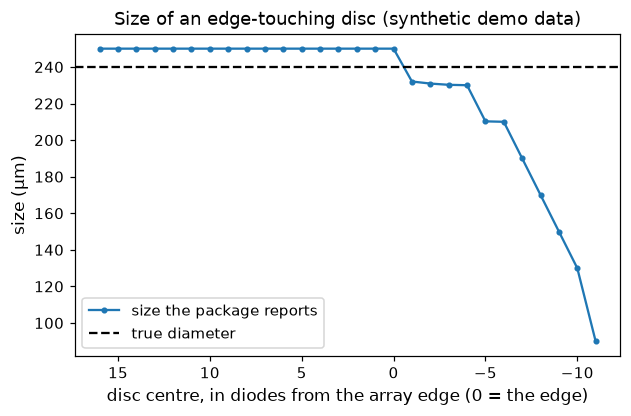

In [4]:
from arrayprobe_enhancements.partial_image_habit import measure, image_groups

for c in centres:
    m = measure(discs[c])
    g = sorted(image_groups(m, NDIODE))
    print(f"centre {c:2d}: N_total {m.n_total:3d}  N_y {m.ny:2d}  N_edge1 {m.n_edge1:2d}  N_edge2 {m.n_edge2:2d}  groups {g}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
scan = list(range(16, -12, -1))
sizes = [engine(disc(c), stock)[1] * PX_UM for c in scan]
ax.plot(scan, sizes, "o-", ms=3, color=_style.KEEP, label="size the package reports")
ax.axhline(D * PX_UM, color=_style.TRUTH, ls="--", label="true diameter")
ax.invert_xaxis()
ax.set_xlabel("disc centre, in diodes from the array edge (0 = the edge)")
ax.set_ylabel("size (µm)")
ax.set_title("Size of an edge-touching disc (synthetic demo data)")
ax.legend(fontsize=10)
fig.savefig("examples/figures/edge_size.png", dpi=110, bbox_inches="tight")
plt.show()

*Figure 2. Size the package reports for a synthetic disc as its centre moves from inside the array past the edge; the dashed line is the true diameter.*

The groups printed above are the module's reading of the paper's rules for this array width
(`rejected_partial`, `accepted_partial`, `complete`, `tiny`; `image_groups` docstring). They
follow $N_{
m edge}$ and $N_{
m total}$ and are not the engine's `touching_edge`: the disc with
centre column 9 is `touching_edge = 't'` and `accepted_partial`, but the one with centre column 16
is `complete` and `'0'`. The paper's ratios are built for partial images; the module gives them
only for a population, and nothing here estimates a single particle's true size. No reconstruction of the missing part is run: the repository has no function
that does it, and the cut-off part is absent from the size.

## 4. How often

Not measured yet: no fraction of particles with `touching_edge` set has been measured
for any campaign or probe. Habit handling of edge images in the UIOOPS releases is described in
the `partial_image_habit` docstring: v3.1.4 classifies the truncated silhouette as if it were
whole; v3.5 withholds a habit for centre-out images and, under the Schima scheme, when edge
contact exceeds half the diameter (`holroyd_new.m:101-104`).

## 5. Check your own data

The product variable is `image_touching_edge` (`arrayprobe_uiops/imgproc.py:401`). The cell turns its three written
values into names and gives the fraction touching. It runs here on a synthetic stand-in.

In [5]:
touching = np.array([0] * 90 + [68] * 8 + [-48] * 2)          # replace with your own variable
names = {t.value: t.name for t in TouchingEdge}
for v in sorted(set(touching.tolist())):
    print(f"{names[v]:10s} ({v:3d}): {np.mean(touching == v):.1%}")

NO_SLICES  (-48): 2.0%
CONTAINED  (  0): 90.0%
TOUCHING   ( 68): 8.0%


## Data summary
The disc positions of section 2 as a labelled dataset, with units.

In [6]:
import xarray as xr
import pandas as pd

ds = xr.Dataset(
    {"size": ("centre", [r[1] * PX_UM for r in rows], {"units": "um"}),
     "touching_edge_written": ("centre", [r[3] for r in rows], {"units": "1 (-48, 0 or 68)"})},
    coords={"centre": ("centre", [r[0] for r in rows], {"units": "diodes"})},
    attrs={"description": "synthetic 24-pixel disc, 32-diode array", "units": "given per variable"})
ds

<xarray.Dataset> Size: 144B
Dimensions:                (centre: 6)
Coordinates:
  * centre                 (centre) int64 48B 16 9 2 -4 -9 -11
Data variables:
    size                   (centre) float64 48B 250.0 250.0 250.0 ... 150.0 90.0
    touching_edge_written  (centre) int64 48B 0 68 68 68 68 68
Attributes:
    description:  synthetic 24-pixel disc, 32-diode array
    units:        given per variable

The same rows as a table: the engine's size and the reject code under the stock and field-campaign limits (labelled `ORACLES limits` in the code).

In [7]:
pd.DataFrame({"centre column (diodes)": [r[0] for r in rows],
              "size (um)": [round(r[1] * PX_UM) for r in rows],
              "reject, stock limits": [r[4] for r in rows],
              "reject, ORACLES limits": [r[5] for r in rows]})

,centre column (diodes),size (um),"reject, stock limits","reject, ORACLES limits"
0,16,250,0,0
1,9,250,0,0
2,2,250,0,0
3,-4,230,0,0
4,-9,150,0,0
5,-11,90,0,a


## 6. Defaults

From [the configuration page](../../docs/06-configuration.md#corrections-engine-35-applies-by-default) and the [enhancements page](../../docs/05-enhancements.md).

| | Default | Turn it on / off |
|---|---|---|
| `touching_edge`, reject `'t'` | always computed; the limits are the preset's (`RejectConfig`) | change `max_edge_img_ar` in the reject configuration |
| `partial_image_habit` | off for every probe, library and driver | opt in by name in the config, or `all = true` |
| `spot_edge_fix` (Korolev table typo, a different edge: the hole/edge ratio) | off for every probe | opt in by name, or `all = true` |

## What to try next

- Move the disc so that it is cut at column 31 and at column 0 and compare `touching_edge`: the engine treats both edges alike.
- Use a 16-pixel disc and watch where the reject code changes.
- Next notebook: [19_two_particles.ipynb](19_two_particles.ipynb) (two drops in one frame).